# Assignment A1: Unsupervised Structure Audit

## 1. Wine Dataset Preparation

This section explores the Wine dataset, examining its feature
scales, distributions and skewness before standardisation.

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings

from sklearn.datasets import load_wine, load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.pipeline import Pipeline
from sklearn.base import clone
import joblib

warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

In [10]:
wine = load_wine()

X_wine = pd.DataFrame(
    wine.data,
    columns=wine.feature_names
)

# Keep labels untouched until the reveal
y_wine_locked = wine.target.copy()

print("Dataset shape:", X_wine.shape)
print("\nFirst five observations:")
display(X_wine.head())

Dataset shape: (178, 13)

First five observations:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [11]:
print("Feature statistics:")
display(X_wine.describe().T)

Feature statistics:


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
malic_acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
alcalinity_of_ash,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
total_phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
nonflavanoid_phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
color_intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


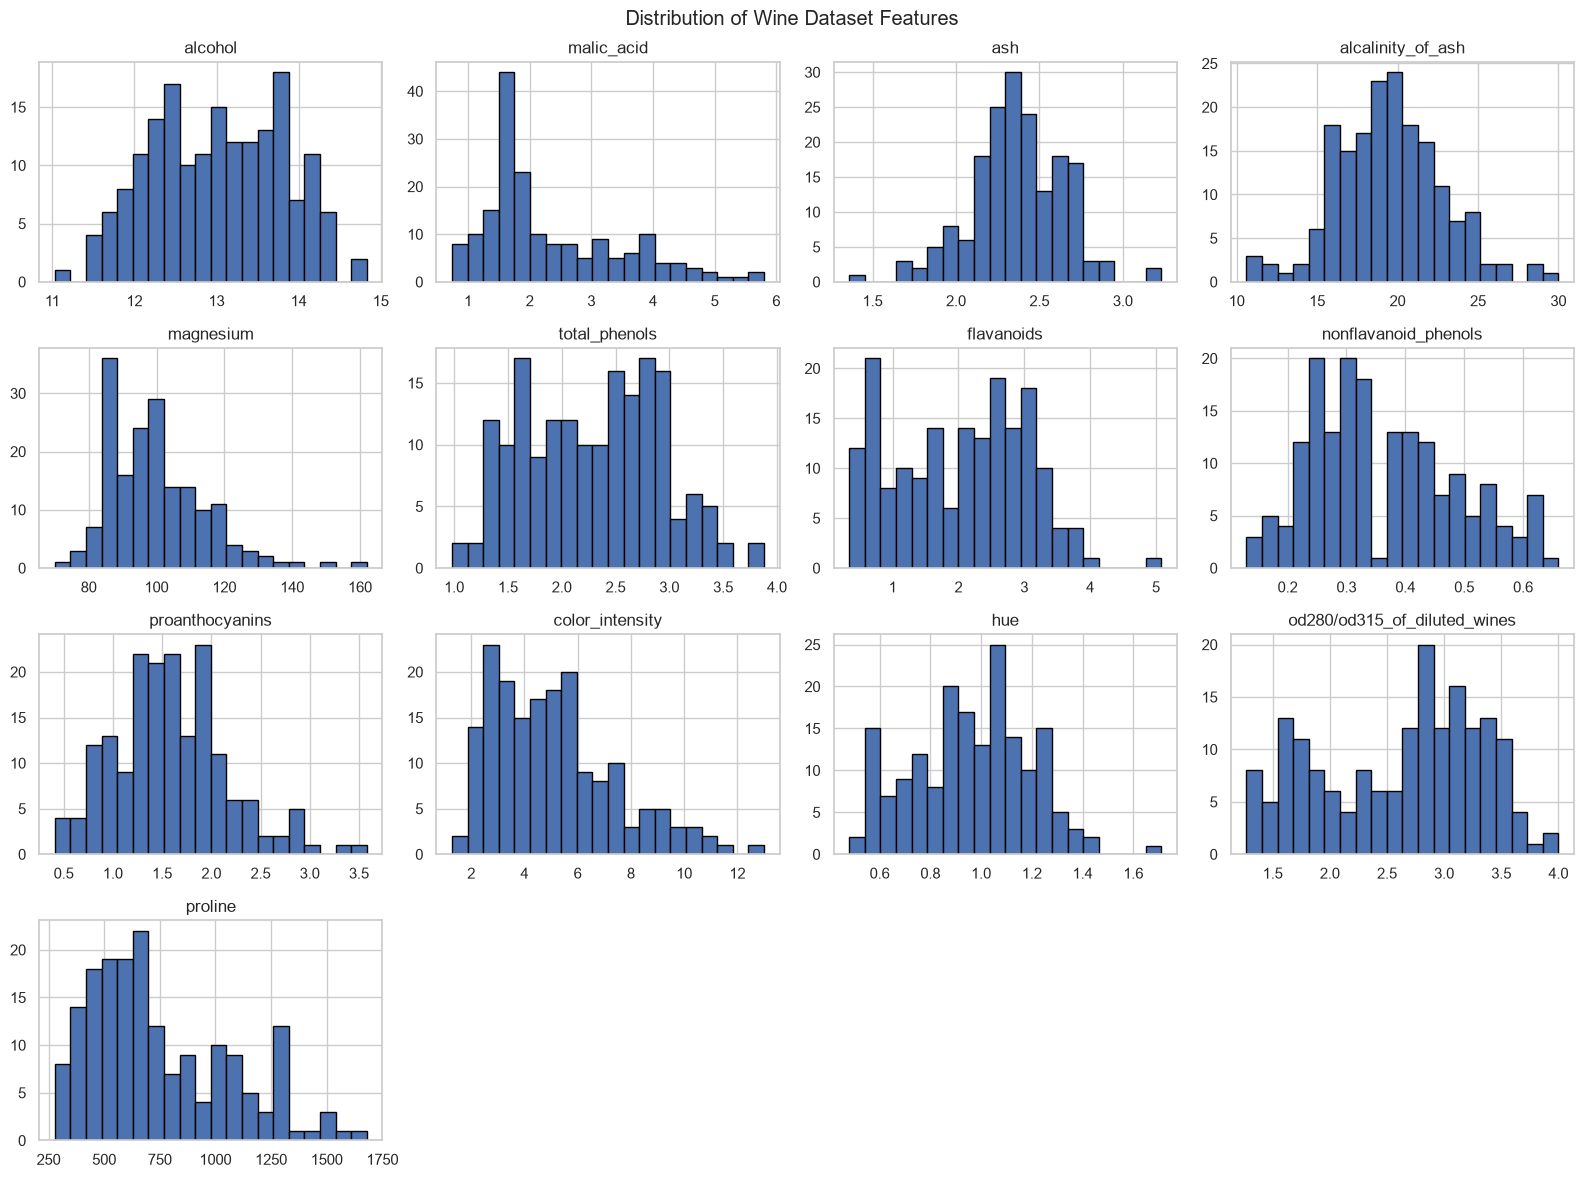

In [12]:
X_wine.hist(
    figsize=(16, 12),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Wine Dataset Features")
plt.tight_layout()
plt.show()

In [13]:
skewness = X_wine.skew().sort_values(
    key=abs,
    ascending=False
)

display(skewness.to_frame(name="Skewness"))

,Skewness
magnesium,1.098191
malic_acid,1.039651
color_intensity,0.868585
proline,0.767822
proanthocyanins,0.517137
nonflavanoid_phenols,0.450151
od280/od315_of_diluted_wines,-0.307285
alcalinity_of_ash,0.213047
ash,-0.176699
total_phenols,0.086639


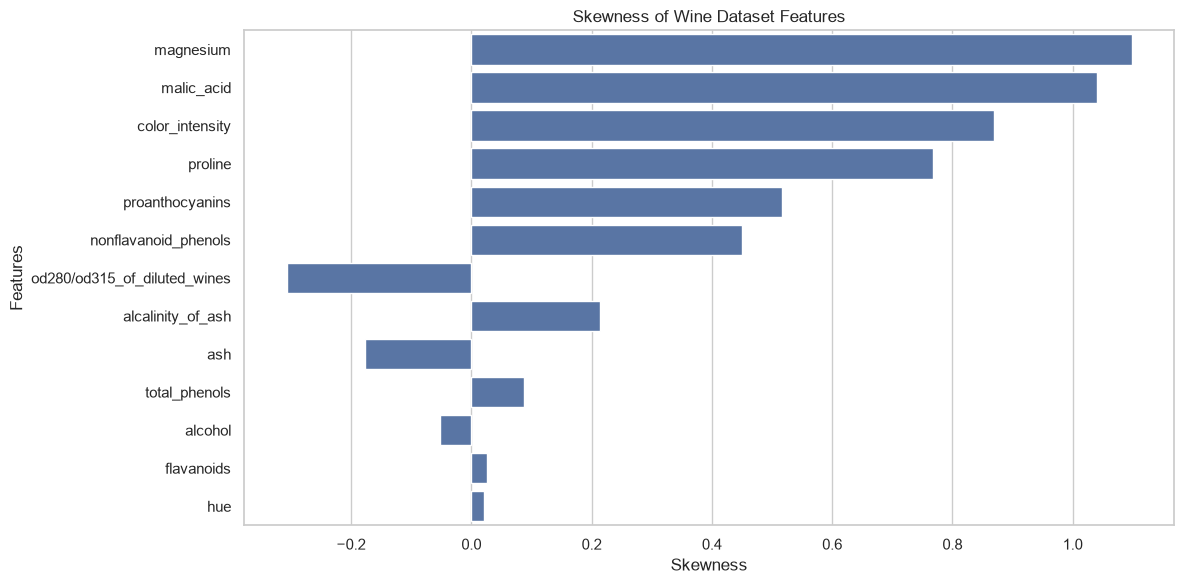

In [14]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=skewness.values,
    y=skewness.index
)

plt.title("Skewness of Wine Dataset Features")
plt.xlabel("Skewness")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [15]:
scaler = StandardScaler()

X_wine_scaled = scaler.fit_transform(X_wine)

X_wine_scaled = pd.DataFrame(
    X_wine_scaled,
    columns=X_wine.columns
)

display(X_wine_scaled.head())

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,1.518613,-0.562250,0.232053,-1.169593,1.913905,0.808997,1.034819,-0.659563,1.224884,0.251717,0.362177,1.847920,1.013009
1,0.246290,-0.499413,-0.827996,-2.490847,0.018145,0.568648,0.733629,-0.820719,-0.544721,-0.293321,0.406051,1.113449,0.965242
2,0.196879,0.021231,1.109334,-0.268738,0.088358,0.808997,1.215533,-0.498407,2.135968,0.269020,0.318304,0.788587,1.395148
3,1.691550,-0.346811,0.487926,-0.809251,0.930918,2.491446,1.466525,-0.981875,1.032155,1.186068,-0.427544,1.184071,2.334574
4,0.295700,0.227694,1.840403,0.451946,1.281985,0.808997,0.663351,0.226796,0.401404,-0.319276,0.362177,0.449601,-0.037874


### 1.1 Data Preparation and Exploration

The Wine dataset consists of 178 observations and 13 numerical chemical measurements. Initial inspection revealed that the features have considerably different measurement scales. For example, alcohol ranges from 11.03 to 14.83, while proline ranges from 278 to 1680. This difference is important because distance-based clustering algorithms such as K-Means are sensitive to feature magnitudes.

The feature distributions were examined using histograms. Several features showed noticeable right skewness, particularly magnesium (1.098), malic acid (1.040), color intensity (0.869), and proline (0.768). Other features, such as alcohol and hue, had distributions that were approximately symmetric.

StandardScaler was selected to standardise the features to approximately zero mean and unit variance. This prevents features with larger numerical ranges from disproportionately influencing distance calculations during clustering.

Although some features exhibited skewness, no additional transformation was applied at this stage. This decision preserves the original feature distributions while addressing the more immediate issue of inconsistent measurement scales.

The resulting standardised dataset was used for subsequent PCA and clustering analysis.

## 2. Wine Principal Component Analysis (PCA)

In [16]:
# Apply PCA to the standardised Wine dataset

pca_full = PCA()

X_wine_pca = pca_full.fit_transform(X_wine_scaled)

explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

print("Explained variance:")
print(explained_variance)

print("\nCumulative explained variance:")
print(cumulative_variance)

Explained variance:
[0.36198848 0.1920749  0.11123631 0.0706903  0.06563294 0.04935823
 0.04238679 0.02680749 0.02222153 0.01930019 0.01736836 0.01298233
 0.00795215]

Cumulative explained variance:
[0.36198848 0.55406338 0.66529969 0.73598999 0.80162293 0.85098116
 0.89336795 0.92017544 0.94239698 0.96169717 0.97906553 0.99204785
 1.        ]


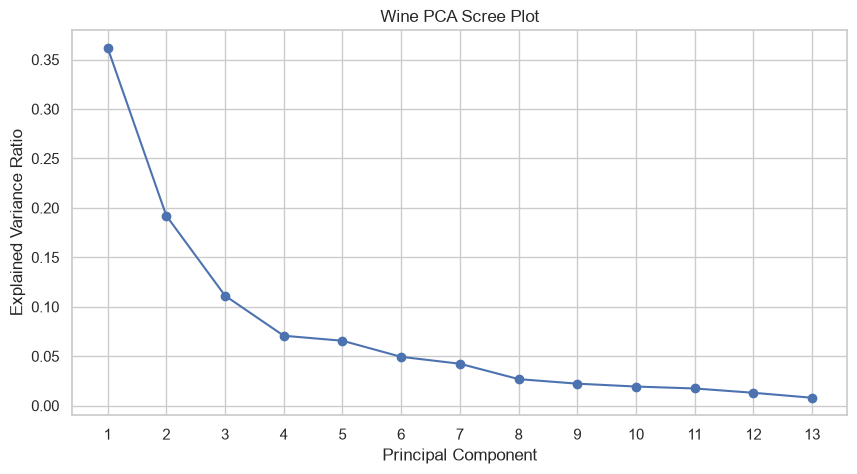

In [18]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(explained_variance) + 1),
    explained_variance,
    marker="o"
)

plt.title("Wine PCA Scree Plot")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.xticks(range(1, 14))
plt.grid(True)
plt.show()

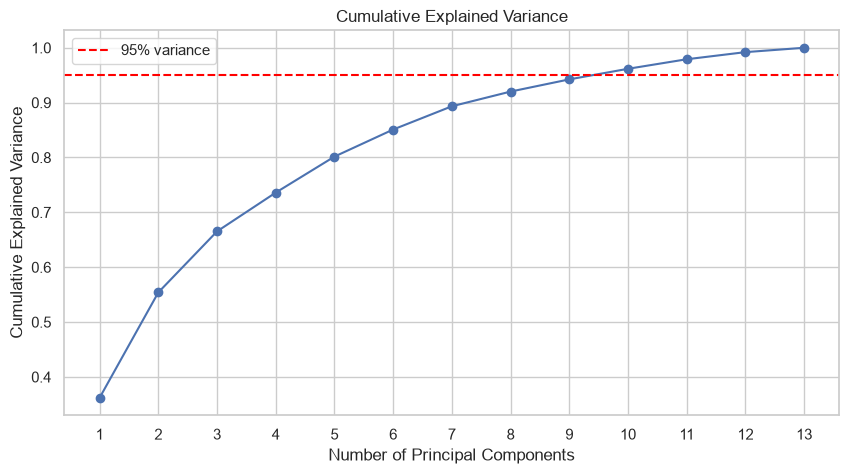

In [19]:
plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(
    y=0.95,
    color="red",
    linestyle="--",
    label="95% variance"
)

plt.title("Cumulative Explained Variance")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.xticks(range(1, 14))
plt.legend()
plt.grid(True)
plt.show()

In [20]:
n_components_95 = np.argmax(
    cumulative_variance >= 0.95
) + 1

print(
    "Components required to retain 95% variance:",
    n_components_95
)

Components required to retain 95% variance: 10


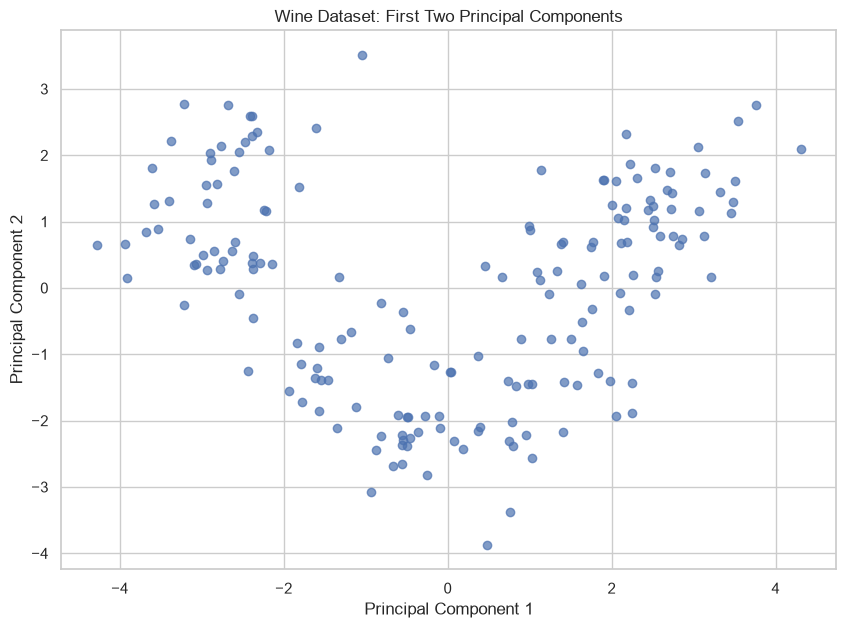

In [21]:
plt.figure(figsize=(10, 7))

plt.scatter(
    X_wine_pca[:, 0],
    X_wine_pca[:, 1],
    alpha=0.7
)

plt.title("Wine Dataset: First Two Principal Components")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.grid(True)
plt.show()

### 2.1 Principal Component Analysis

PCA was applied to the standardised Wine dataset to examine its dimensionality and determine how much information could be retained through dimensionality reduction.

The first principal component explains approximately 36.20% of the total variance, while the second explains 19.21%. Together, they account for approximately 55.41% of the dataset's variance.

The cumulative explained variance increases as additional components are included. The first five components retain approximately 80.16% of the variance, while the first ten retain approximately 96.17%.

Based on the 95% variance threshold, ten principal components were selected. This reduces the dataset from 13 original features to 10 principal components while preserving more than 95% of the original variance.

Although retaining only two components would provide greater dimensionality reduction, the resulting 55.41% explained variance may discard substantial information. Therefore, ten components provide a more suitable balance when the priority is retaining information.

The first two principal components were also visualised to explore the overall structure and possible grouping patterns in the dataset without using the original class labels.

## 3. Wine Clustering

### 3.1 K-Means Clustering

The elbow method is used to examine how within-cluster
sum of squares (inertia) changes as the number of clusters
increases.

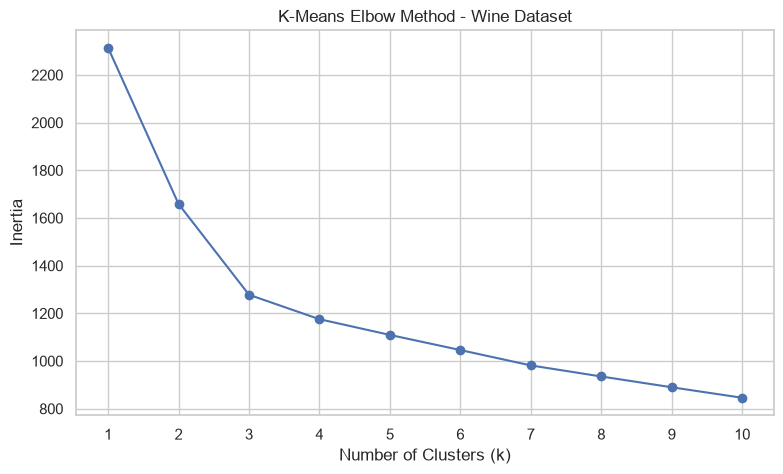

In [22]:

# Calculate inertia for different numbers of clusters

inertia_values = []
k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_wine_scaled)
    inertia_values.append(kmeans.inertia_)

# Plot the elbow curve
plt.figure(figsize=(9, 5))

plt.plot(
    k_values,
    inertia_values,
    marker="o"
)

plt.title("K-Means Elbow Method - Wine Dataset")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.xticks(k_values)
plt.grid(True)
plt.show()


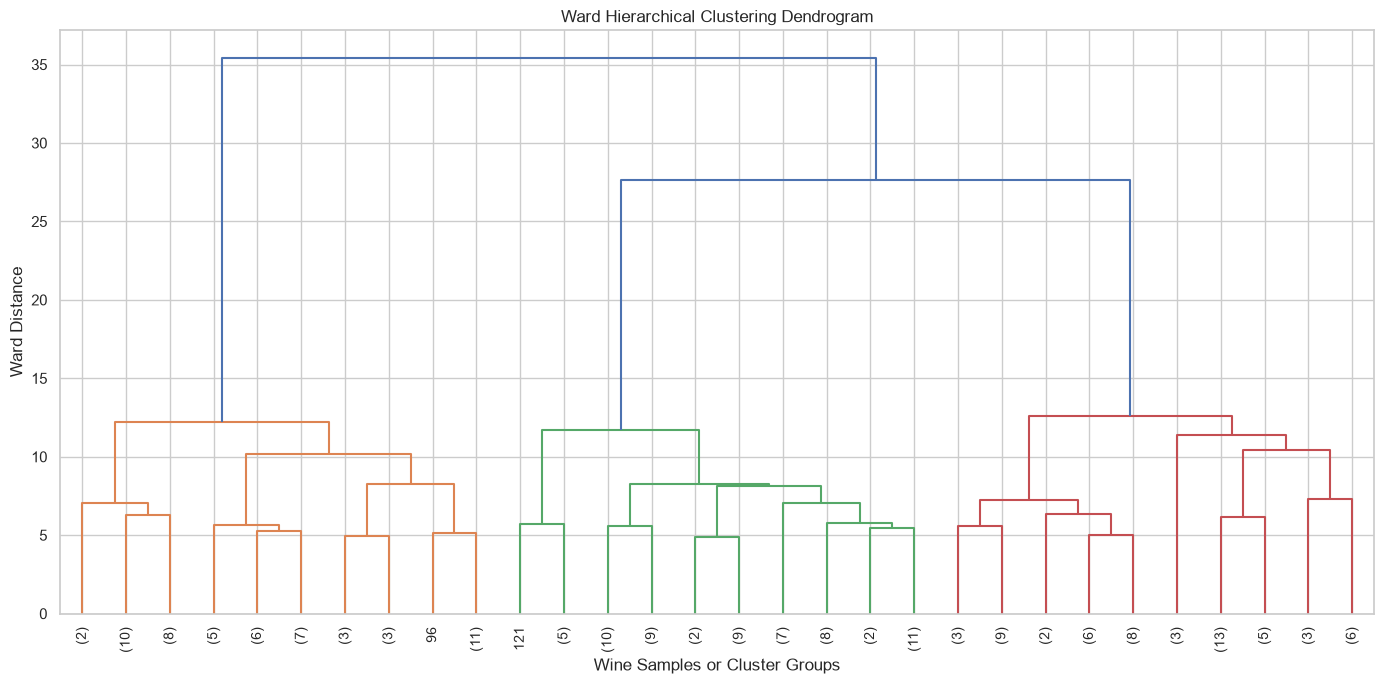

In [23]:

# Perform hierarchical clustering using Ward's method

linkage_matrix = linkage(
    X_wine_scaled,
    method="ward"
)

# Plot dendrogram
plt.figure(figsize=(14, 7))

dendrogram(
    linkage_matrix,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=90,
    leaf_font_size=10
)

plt.title("Ward Hierarchical Clustering Dendrogram")
plt.xlabel("Wine Samples or Cluster Groups")
plt.ylabel("Ward Distance")
plt.tight_layout()
plt.show()


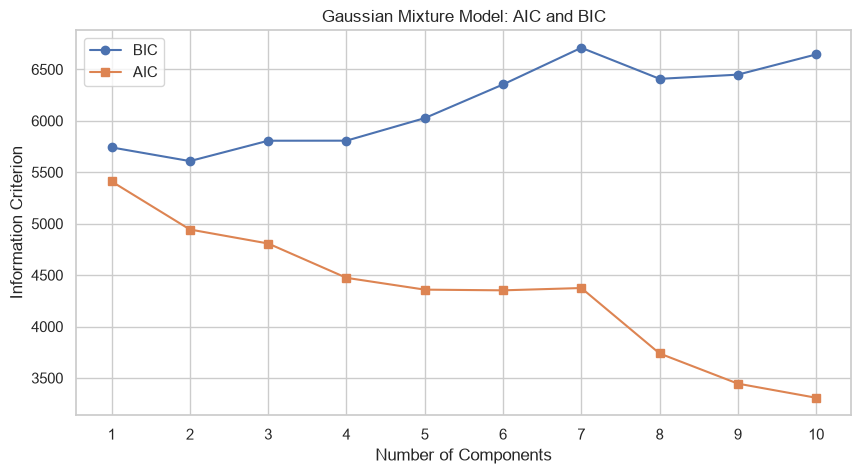

Best BIC component count: 2
Best AIC component count: 10


In [24]:

# Compare Gaussian Mixture Models

gmm_bic = []
gmm_aic = []
gmm_components = range(1, 11)

for k in gmm_components:
    gmm = GaussianMixture(
        n_components=k,
        random_state=42,
        n_init=5
    )

    gmm.fit(X_wine_scaled)

    gmm_bic.append(gmm.bic(X_wine_scaled))
    gmm_aic.append(gmm.aic(X_wine_scaled))

# Plot BIC and AIC
plt.figure(figsize=(10, 5))

plt.plot(
    gmm_components,
    gmm_bic,
    marker="o",
    label="BIC"
)

plt.plot(
    gmm_components,
    gmm_aic,
    marker="s",
    label="AIC"
)

plt.title("Gaussian Mixture Model: AIC and BIC")
plt.xlabel("Number of Components")
plt.ylabel("Information Criterion")
plt.xticks(list(gmm_components))
plt.legend()
plt.grid(True)
plt.show()

print("Best BIC component count:",
      list(gmm_components)[np.argmin(gmm_bic)])

print("Best AIC component count:",
      list(gmm_components)[np.argmin(gmm_aic)])


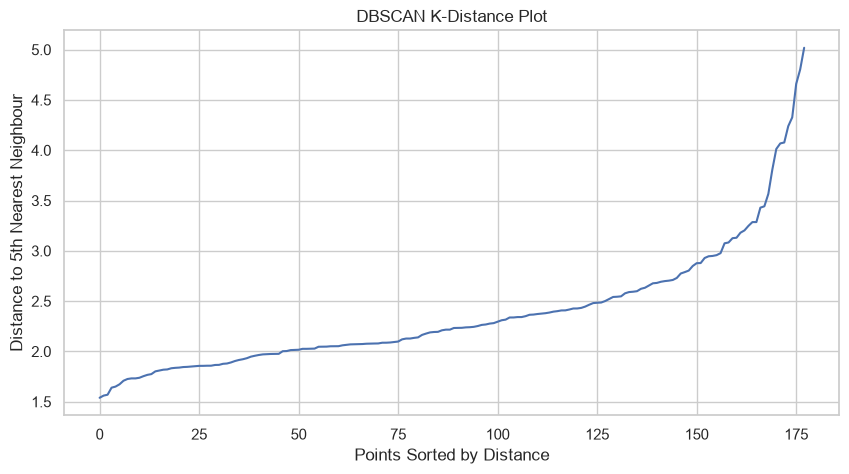

In [25]:

# Determine a suitable eps value using a k-distance plot

min_samples = 5

neighbors = NearestNeighbors(
    n_neighbors=min_samples
)

neighbors.fit(X_wine_scaled)

distances, indices = neighbors.kneighbors(X_wine_scaled)

# Sort the distances to the 5th nearest neighbour
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(10, 5))

plt.plot(k_distances)

plt.title("DBSCAN K-Distance Plot")
plt.xlabel("Points Sorted by Distance")
plt.ylabel("Distance to 5th Nearest Neighbour")
plt.grid(True)
plt.show()


### 3.5 Implementation and Comparison of Clustering Algorithms

In [26]:

# 1. K-Means
kmeans_model = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans_model.fit_predict(X_wine_scaled)


# 2. Ward Hierarchical Clustering
ward_model = AgglomerativeClustering(
    n_clusters=3,
    linkage="ward"
)

ward_labels = ward_model.fit_predict(X_wine_scaled)


# 3. Gaussian Mixture Model
gmm_model = GaussianMixture(
    n_components=3,
    random_state=42,
    n_init=5
)

gmm_labels = gmm_model.fit_predict(X_wine_scaled)


# 4. DBSCAN
dbscan_model = DBSCAN(
    eps=0.8,
    min_samples=5
)

dbscan_labels = dbscan_model.fit_predict(X_wine_scaled)


print("Clustering completed successfully!")


Clustering completed successfully!


In [27]:

# Compare clustering algorithms using silhouette scores

clustering_results = {
    "K-Means": kmeans_labels,
    "Ward Hierarchical": ward_labels,
    "Gaussian Mixture": gmm_labels,
    "DBSCAN": dbscan_labels
}

for name, labels in clustering_results.items():

    unique_clusters = set(labels)
    n_clusters = len(unique_clusters - {-1})

    if name == "DBSCAN":
        mask = labels != -1
        valid_labels = labels[mask]
        valid_data = X_wine_scaled.values[mask]

        if len(set(valid_labels)) >= 2:
            score = silhouette_score(
                valid_data,
                valid_labels
            )
            print(f"{name}: {score:.4f}")
        else:
            print(f"{name}: Silhouette score unavailable")

    elif n_clusters >= 2:
        score = silhouette_score(
            X_wine_scaled,
            labels
        )
        print(f"{name}: {score:.4f}")

    else:
        print(f"{name}: Silhouette score unavailable")


K-Means: 0.2849
Ward Hierarchical: 0.2774
Gaussian Mixture: 0.2844
DBSCAN: Silhouette score unavailable


In [28]:

# Display cluster sizes

for name, labels in clustering_results.items():

    unique, counts = np.unique(
        labels,
        return_counts=True
    )

    print(f"\n{name}")

    for cluster, count in zip(unique, counts):
        if cluster == -1:
            print(f"Noise points: {count}")
        else:
            print(f"Cluster {cluster}: {count} observations")



K-Means
Cluster 0: 65 observations
Cluster 1: 51 observations
Cluster 2: 62 observations

Ward Hierarchical
Cluster 0: 58 observations
Cluster 1: 56 observations
Cluster 2: 64 observations

Gaussian Mixture
Cluster 0: 63 observations
Cluster 1: 64 observations
Cluster 2: 51 observations

DBSCAN
Noise points: 178


In [29]:

# Test different eps values for DBSCAN

eps_values = [0.8, 1.0, 1.2, 1.4, 1.6, 1.8, 2.0, 2.2, 2.5, 3.0]

print("DBSCAN parameter comparison\n")

for eps in eps_values:

    model = DBSCAN(
        eps=eps,
        min_samples=5
    )

    labels = model.fit_predict(X_wine_scaled)

    n_clusters = len(set(labels) - {-1})
    n_noise = np.sum(labels == -1)

    print(
        f"eps={eps:<4} | "
        f"Clusters={n_clusters:<3} | "
        f"Noise points={n_noise}"
    )


DBSCAN parameter comparison

eps=0.8  | Clusters=0   | Noise points=178
eps=1.0  | Clusters=0   | Noise points=178
eps=1.2  | Clusters=0   | Noise points=178
eps=1.4  | Clusters=0   | Noise points=178
eps=1.6  | Clusters=3   | Noise points=162
eps=1.8  | Clusters=7   | Noise points=118
eps=2.0  | Clusters=5   | Noise points=85
eps=2.2  | Clusters=2   | Noise points=55
eps=2.5  | Clusters=1   | Noise points=24
eps=3.0  | Clusters=1   | Noise points=11


In [30]:

# Compare DBSCAN silhouette scores across eps values

dbscan_comparison = []

for eps in eps_values:

    model = DBSCAN(
        eps=eps,
        min_samples=5
    )

    labels = model.fit_predict(X_wine_scaled)

    mask = labels != -1
    valid_labels = labels[mask]
    valid_data = X_wine_scaled.values[mask]

    n_clusters = len(set(valid_labels))
    n_noise = np.sum(~mask)

    if n_clusters >= 2 and len(valid_labels) > n_clusters:
        score = silhouette_score(
            valid_data,
            valid_labels
        )
    else:
        score = np.nan

    dbscan_comparison.append({
        "eps": eps,
        "clusters": n_clusters,
        "noise_points": n_noise,
        "silhouette": score
    })

dbscan_results = pd.DataFrame(dbscan_comparison)

display(dbscan_results)


,eps,clusters,noise_points,silhouette
0,0.8,0,178,NaN
1,1.0,0,178,NaN
2,1.2,0,178,NaN
3,1.4,0,178,NaN
4,1.6,3,162,0.502071
5,1.8,7,118,0.246187
6,2.0,5,85,0.240461
7,2.2,2,55,0.348012
8,2.5,1,24,NaN
9,3.0,1,11,NaN


In [31]:
print(dbscan_results.to_string(index=False))

 eps  clusters  noise_points  silhouette
 0.8         0           178         NaN
 1.0         0           178         NaN
 1.2         0           178         NaN
 1.4         0           178         NaN
 1.6         3           162    0.502071
 1.8         7           118    0.246187
 2.0         5            85    0.240461
 2.2         2            55    0.348012
 2.5         1            24         NaN
 3.0         1            11         NaN


### 3.7 Preliminary Clustering Analysis

Four unsupervised clustering algorithms were investigated using the standardised Wine dataset.

K-Means, Ward Hierarchical Clustering and Gaussian Mixture Models were initially evaluated using three clusters. Their silhouette scores were 0.2849, 0.2774 and 0.2844 respectively.

K-Means produced the highest silhouette score, although its performance was very close to that of the Gaussian Mixture Model. Ward Hierarchical Clustering also produced a comparable result.

The three algorithms produced reasonably balanced cluster sizes, suggesting that the data can be partitioned into three groups under these configurations.

Gaussian Mixture Model selection produced different results depending on the information criterion used. BIC favoured two components, while AIC favoured ten components. This difference demonstrates that the estimated number of groups can depend on the model selection criterion.

The initial DBSCAN configuration, using an epsilon value of 0.8 and five minimum samples, classified all 178 observations as noise. This indicates that the initial neighbourhood radius was too restrictive. Further parameter investigation is required before drawing conclusions about DBSCAN's performance.

These findings remain preliminary because the final cluster configuration must be evaluated alongside the elbow curve, dendrogram, GMM information criteria and DBSCAN parameter investigation.

In [32]:
dbscan_model = DBSCAN(
    eps=2.2,
    min_samples=5
)

dbscan_labels = dbscan_model.fit_predict(X_wine_scaled)

print("DBSCAN clusters:", len(set(dbscan_labels) - {-1}))
print("DBSCAN noise points:", np.sum(dbscan_labels == -1))

DBSCAN clusters: 2
DBSCAN noise points: 55


DBSCAN Clustering Analysis

DBSCAN was initially tested with an epsilon value of 0.8, but all 178 observations were classified as noise. To improve the clustering results, several epsilon values were evaluated while keeping `min_samples=5` constant.

The parameter comparison showed that `eps=1.6` produced the highest silhouette score of 0.5021, but classified 162 observations as noise. At `eps=2.2`, DBSCAN identified two clusters and 55 noise points, achieving a silhouette score of 0.3480.

Although the smaller epsilon value produced a higher silhouette score, it excluded most of the dataset. Therefore, `eps=2.2` was selected as a more practical compromise between cluster separation and the number of observations assigned to clusters. This demonstrates the importance of considering both clustering quality and noise points when evaluating DBSCAN.

In [33]:
for n in [2, 3, 10]:
    gmm = GaussianMixture(
        n_components=n,
        random_state=42,
        n_init=5
    )

    labels = gmm.fit_predict(X_wine_scaled)

    score = silhouette_score(X_wine_scaled, labels)

    print(
        f"Components: {n} | "
        f"Silhouette: {score:.4f} | "
        f"BIC: {gmm.bic(X_wine_scaled):.2f} | "
        f"AIC: {gmm.aic(X_wine_scaled):.2f}"
    )

Components: 2 | Silhouette: 0.2685 | BIC: 5608.35 | AIC: 4943.36
Components: 3 | Silhouette: 0.2844 | BIC: 5806.29 | AIC: 4807.21
Components: 10 | Silhouette: 0.1476 | BIC: 6645.41 | AIC: 3307.72


Gaussian Mixture Model Selection

Gaussian Mixture Models with 2, 3 and 10 components were compared using the Akaike Information Criterion (AIC), Bayesian Information Criterion (BIC) and silhouette score.

The BIC selected 2 components, with a value of 5608.35, while the AIC selected 10 components, with a value of 3307.72. However, the three-component model achieved the highest silhouette score of 0.2844.

The disagreement between these evaluation measures indicates that the preferred number of components depends on the selection criterion. BIC favours a simpler model, AIC favours a more complex model, while the silhouette score evaluates how well-separated the resulting clusters are. The three-component solution was retained for comparison with K-Means and Ward hierarchical clustering, but it should not be interpreted as definitive evidence that the dataset contains exactly three natural groups.

In [34]:
# Load the Digits dataset
digits = load_digits()

X_digits = digits.data

# Keep the labels locked until the commitment note
y_digits_locked = digits.target.copy()

print("Dataset shape:", X_digits.shape)
print("Number of features:", X_digits.shape[1])
print("Number of observations:", X_digits.shape[0])

Dataset shape: (1797, 64)
Number of features: 64
Number of observations: 1797


In [35]:
# Apply PCA while retaining 95% variance
pca_digits = PCA(n_components=0.95)

X_digits_pca = pca_digits.fit_transform(X_digits)

print("Original number of features:", X_digits.shape[1])
print("Reduced number of features:", X_digits_pca.shape[1])
print(
    "Explained variance retained:",
    round(np.sum(pca_digits.explained_variance_ratio_) * 100, 2),
    "%"
)

Original number of features: 64
Reduced number of features: 29
Explained variance retained: 95.48 %


In [36]:
# K-Means WITHOUT PCA
start_time = time.perf_counter()

kmeans_digits_original = KMeans(
    n_clusters=10,
    random_state=42,
    n_init=10
)

labels_original = kmeans_digits_original.fit_predict(X_digits)

time_original = time.perf_counter() - start_time
inertia_original = kmeans_digits_original.inertia_


# K-Means WITH PCA
start_time = time.perf_counter()

kmeans_digits_pca = KMeans(
    n_clusters=10,
    random_state=42,
    n_init=10
)

labels_pca = kmeans_digits_pca.fit_predict(X_digits_pca)

time_pca = time.perf_counter() - start_time
inertia_pca = kmeans_digits_pca.inertia_


# Display comparison
print("WITHOUT PCA")
print("Inertia:", round(inertia_original, 2))
print("Runtime:", round(time_original, 4), "seconds")

print("\nWITH PCA")
print("Inertia:", round(inertia_pca, 2))
print("Runtime:", round(time_pca, 4), "seconds")

WITHOUT PCA
Inertia: 1165256.3
Runtime: 0.3812 seconds

WITH PCA
Inertia: 1068958.08
Runtime: 0.1029 seconds


Digits Clustering: With and Without PCA

K-Means clustering was performed on the original Digits dataset and on a PCA-transformed version retaining 95% of the variance.

The original dataset contained 64 features, while PCA reduced this to 29 components, retaining 95.48% of the variance.

Without PCA, K-Means achieved an inertia of 1,165,256.30 and a runtime of 0.3812 seconds. With PCA, the inertia was 1,068,958.08 and the runtime decreased to 0.1029 seconds.

The PCA-based experiment was approximately 73% faster in this run. This suggests that dimensionality reduction can improve computational efficiency while retaining most of the dataset's variance. However, the inertia values are calculated in different feature spaces and should not be treated as directly comparable measures of clustering quality.

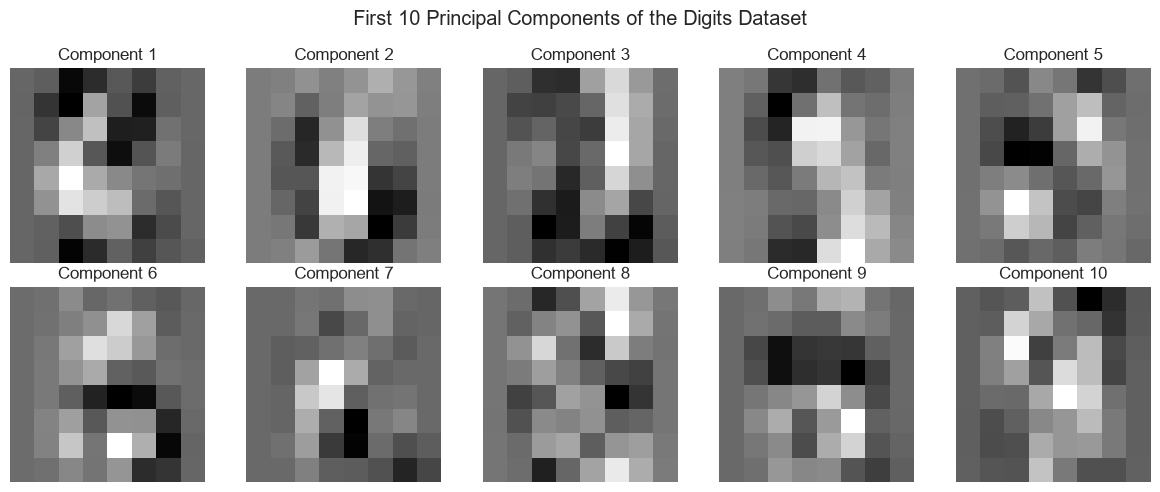

In [37]:
# Display the first 10 PCA components
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    component_image = pca_digits.components_[i].reshape(8, 8)

    ax.imshow(component_image, cmap="gray")
    ax.set_title(f"Component {i + 1}")
    ax.axis("off")

plt.suptitle("First 10 Principal Components of the Digits Dataset")
plt.tight_layout()
plt.show()

In [38]:
# Standardise the original Digits data
digits_scaler = StandardScaler()
X_digits_scaled = digits_scaler.fit_transform(X_digits)

# Run K-Means on scaled data
start_time = time.perf_counter()

kmeans_digits_scaled = KMeans(
    n_clusters=10,
    random_state=42,
    n_init=10
)

labels_scaled = kmeans_digits_scaled.fit_predict(X_digits_scaled)

time_scaled = time.perf_counter() - start_time

# Compare results
print("WITHOUT SCALING")
print("Inertia:", round(inertia_original, 2))
print("Runtime:", round(time_original, 4), "seconds")

print("\nWITH SCALING")
print("Inertia:", round(kmeans_digits_scaled.inertia_, 2))
print("Runtime:", round(time_scaled, 4), "seconds")

WITHOUT SCALING
Inertia: 1165256.3
Runtime: 0.3812 seconds

WITH SCALING
Inertia: 69813.56
Runtime: 0.1839 seconds


Effect of Feature Scaling on the Digits Dataset

The effect of standardisation was investigated by comparing K-Means clustering on the original Digits dataset and its standardised version.

Without scaling, the model achieved an inertia of 1,165,256.30 and a runtime of 0.3812 seconds. With standardisation, the inertia decreased to 69,813.56 and the runtime was 0.1839 seconds.

However, the inertia values are not directly comparable because standardisation changes the scale and relative weighting of the pixel features. Since all pixel values originally share the same range of 0 to 16, standardisation was not considered essential for the primary experiment. The unscaled dataset was therefore retained for the main comparison, while the scaled experiment was included to demonstrate the effect of preprocessing.

In [39]:
import os
import joblib

from src.clustering import build_wine_pipeline

# Create the models folder if it doesn't exist
os.makedirs("models", exist_ok=True)

# Build the pipeline
wine_pipeline = build_wine_pipeline(
    n_clusters=3,
    variance=0.95
)

# Fit using the ORIGINAL, unscaled Wine data
wine_pipeline.fit(X_wine)

# Save the trained pipeline
joblib.dump(
    wine_pipeline,
    "models/wine_pipeline.joblib"
)

print("Wine pipeline trained and saved successfully!")

ModuleNotFoundError: No module named 'src'

In [40]:
import os

print(os.getcwd())
print(os.listdir())

c:\Users\HP\OneDrive\Documents\unsupervised-structure-audit\notebooks
['A1_unsupervised_audit.ipynb']


In [41]:
import os
import sys

# Move from notebooks folder to the main project folder
os.chdir("..")

# Add the project folder to Python's import path
sys.path.insert(0, os.getcwd())

print("Working directory:", os.getcwd())
print("Project files:", os.listdir())

Working directory: c:\Users\HP\OneDrive\Documents\unsupervised-structure-audit
Project files: ['.git', 'models', 'notebooks', 'README.md', 'requirements.txt', 'src', 'tests', 'venv']


In [42]:
from src.clustering import build_wine_pipeline

In [43]:
import os
import joblib
from src.clustering import build_wine_pipeline

os.makedirs("models", exist_ok=True)

wine_pipeline = build_wine_pipeline(n_clusters=3, variance=0.95)

wine_pipeline.fit(X_wine)

joblib.dump(wine_pipeline, "models/wine_pipeline.joblib")

print("Wine pipeline trained and saved successfully!")

Wine pipeline trained and saved successfully!


## Reference Label Reveal

The pre-reveal commitment note has been committed to Git.
I can now access the reference labels to evaluate how closely
the unsupervised clustering results correspond to the actual classes.

In [44]:
# Reveal the reference labels after committing the pre-reveal note

y_wine = y_wine_locked.copy()
y_digits = y_digits_locked.copy()

print("Wine reference labels revealed.")
print("Wine class distribution:")
print(pd.Series(y_wine).value_counts().sort_index())

print("\nDigits reference labels revealed.")
print("Digits class distribution:")
print(pd.Series(y_digits).value_counts().sort_index())

Wine reference labels revealed.
Wine class distribution:
0    59
1    71
2    48
Name: count, dtype: int64

Digits reference labels revealed.
Digits class distribution:
0    178
1    182
2    177
3    183
4    181
5    182
6    181
7    179
8    174
9    180
Name: count, dtype: int64


## Evaluation Against Reference Labels

The reference labels are now used to evaluate the clustering results.
External evaluation metrics are used to measure the agreement between
the discovered clusters and the actual dataset classes.

In [45]:
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    homogeneity_completeness_v_measure
)
from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

# Refit DBSCAN using the selected parameters
dbscan_final = DBSCAN(eps=2.2, min_samples=5)
dbscan_labels_final = dbscan_final.fit_predict(X_wine_scaled)

# Collect Wine clustering results
wine_clusterings = {
    "K-Means": kmeans_labels,
    "Ward": ward_labels,
    "Gaussian Mixture": gmm_labels,
    "DBSCAN": dbscan_labels_final
}

# Calculate evaluation metrics
wine_results = []

for name, labels in wine_clusterings.items():
    homogeneity, completeness, v_measure = (
        homogeneity_completeness_v_measure(y_wine, labels)
    )

    wine_results.append({
        "Algorithm": name,
        "ARI": adjusted_rand_score(y_wine, labels),
        "NMI": normalized_mutual_info_score(y_wine, labels),
        "Homogeneity": homogeneity,
        "Completeness": completeness,
        "V-measure": v_measure
    })

wine_evaluation = pd.DataFrame(wine_results)

print("WINE CLUSTERING EVALUATION")
display(wine_evaluation.round(4))

WINE CLUSTERING EVALUATION


,Algorithm,ARI,NMI,Homogeneity,Completeness,V-measure
0,K-Means,0.8975,0.8759,0.8788,0.8730,0.8759
1,Ward,0.7899,0.7865,0.7904,0.7825,0.7865
2,Gaussian Mixture,0.8804,0.8609,0.8639,0.8580,0.8609
3,DBSCAN,0.3291,0.4191,0.4104,0.4282,0.4191


### Wine Clustering Evaluation

The evaluation shows that K-Means achieved the strongest agreement with the reference labels, recording an ARI of 0.8975 and an NMI of 0.8759. Gaussian Mixture also performed strongly, with an ARI of 0.8804 and NMI of 0.8609. Ward hierarchical clustering achieved reasonable results, while DBSCAN performed considerably worse.

These findings suggest that K-Means was the most effective of the four algorithms for recovering the underlying class structure in this dataset.

An important observation is that the silhouette scores obtained before revealing the labels were relatively modest, despite the strong ARI and NMI scores. This demonstrates that internal clustering metrics and external evaluation metrics measure different aspects of clustering quality.

In [46]:
from sklearn.cluster import KMeans
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    homogeneity_score,
    completeness_score,
    v_measure_score
)

# Train K-Means without PCA
digits_kmeans_no_pca = KMeans(
    n_clusters=10,
    random_state=42,
    n_init=10
)

digits_labels_no_pca = digits_kmeans_no_pca.fit_predict(X_digits)

# Train K-Means with PCA
digits_kmeans_pca = KMeans(
    n_clusters=10,
    random_state=42,
    n_init=10
)

digits_labels_pca = digits_kmeans_pca.fit_predict(X_digits_pca)

# Evaluation function
def evaluate_clustering(true_labels, predicted_labels):
    return {
        "ARI": adjusted_rand_score(true_labels, predicted_labels),
        "NMI": normalized_mutual_info_score(true_labels, predicted_labels),
        "Homogeneity": homogeneity_score(true_labels, predicted_labels),
        "Completeness": completeness_score(true_labels, predicted_labels),
        "V-measure": v_measure_score(true_labels, predicted_labels)
    }

# Evaluate both approaches
digits_results = pd.DataFrame([
    {
        "Approach": "Without PCA",
        **evaluate_clustering(y_digits, digits_labels_no_pca)
    },
    {
        "Approach": "With PCA",
        **evaluate_clustering(y_digits, digits_labels_pca)
    }
])

digits_results.round(4)

,Approach,ARI,NMI,Homogeneity,Completeness,V-measure
0,Without PCA,0.6669,0.7394,0.7353,0.7436,0.7394
1,With PCA,0.6625,0.7377,0.7340,0.7413,0.7377


### Digits Clustering Evaluation

The Digits dataset was evaluated using K-Means with ten clusters, both with and without PCA.

Without PCA, the model achieved an ARI of 0.6669 and an NMI of 0.7394. With PCA, it achieved an ARI of 0.6625 and an NMI of 0.7377.

The results show that the approach without PCA performed marginally better across all evaluation metrics. However, the differences were very small, indicating that PCA reduced the dimensionality from 64 to 29 components while preserving most of the clustering information.

This suggests that dimensionality reduction improved computational efficiency without significantly affecting clustering quality. The results also provide reasonable support for the initial prediction of ten clusters, although some handwritten digit classes remain difficult to distinguish perfectly.